In [1]:
#pip install plotnine

In [48]:
import pandas as pd
from plotnine import ggplot, geom_bar, aes, geom_col, labs, theme, element_blank, element_text, geom_point, geom_histogram, facet_wrap, geom_line, scale_y_log10
import re
from datetime import datetime

In [3]:
# First, download the metadata CSV file
METADATA = "sequence_metadata/sequence_metadata_07012024.csv"
metadata = pd.read_csv(METADATA, sep = ",")
metadata.head()
# This dataset has H5NX alphainfluenza sequences uploaded to NCBI Virus, collected from North American birds between Jan. 1, 2022 and Jun. 14, 2024

,Accession,Organism_Name,SRA_Accession,Organization,Org_location,Release_Date,Isolate,Species,Molecule_type,Length,...,Segment,Geo_Location,Country,USA,Host,Isolation_Source,Collection_Date,BioSample,BioProject,GenBank_Title
0,PP929863.1,Influenza A virus,NaN,"Servicio Nacional de Sanidad, Inocuidad, y Cal...",Mexico,2024-06-23,CPA-01654-24,Alphainfluenzavirus influenzae,ssRNA(-),2313,...,1,"Mexico: EdoMex,texcoco",Mexico,NaN,Gallus gallus,"spleen, abdominal cavity, lung",2024-02-29,NaN,NaN,Influenza A virus (A/Gallus gallus/texcoco/CPA...
1,PP929864.1,Influenza A virus,NaN,"Servicio Nacional de Sanidad, Inocuidad, y Cal...",Mexico,2024-06-23,CPA-01654-24,Alphainfluenzavirus influenzae,ssRNA(-),2315,...,2,"Mexico: EdoMex,texcoco",Mexico,NaN,Gallus gallus,"spleen, abdominal cavity, lung",2024-02-29,NaN,NaN,Influenza A virus (A/Gallus gallus/texcoco/CPA...
2,PP929865.1,Influenza A virus,NaN,"Servicio Nacional de Sanidad, Inocuidad, y Cal...",Mexico,2024-06-23,CPA-01654-24,Alphainfluenzavirus influenzae,ssRNA(-),2207,...,3,"Mexico: EdoMex,texcoco",Mexico,NaN,Gallus gallus,"spleen, abdominal cavity, lung",2024-02-29,NaN,NaN,Influenza A virus (A/Gallus gallus/texcoco/CPA...
3,PP929866.1,Influenza A virus,NaN,"Servicio Nacional de Sanidad, Inocuidad, y Cal...",Mexico,2024-06-23,CPA-01654-24,Alphainfluenzavirus influenzae,ssRNA(-),1729,...,4,"Mexico: EdoMex,texcoco",Mexico,NaN,Gallus gallus,"spleen, abdominal cavity, lung",2024-02-29,NaN,NaN,Influenza A virus (A/Gallus gallus/texcoco/CPA...
4,PP929867.1,Influenza A virus,NaN,"Servicio Nacional de Sanidad, Inocuidad, y Cal...",Mexico,2024-06-23,CPA-01654-24,Alphainfluenzavirus influenzae,ssRNA(-),1539,...,5,"Mexico: EdoMex,texcoco",Mexico,NaN,Gallus gallus,"spleen, abdominal cavity, lung",2024-02-29,NaN,NaN,Influenza A virus (A/Gallus gallus/texcoco/CPA...


In [6]:
# Keep entry only if Collection Date matches YYYY-MM-DD format 
metadata_filtered = metadata[metadata["Collection_Date"].str.match(r"^\d{4}-\d{2}-\d{2}$")]

In [7]:
#metadata_filtered.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/metadata_filtered_test.csv", sep=",")

In [8]:
# # How to: format a string as a date
# x = "2024-05-01"
# from datetime import datetime 
# date_obj = datetime.strptime(x, '%Y-%m-%d')
# print(date_obj)
# print(type(date_obj))

In [9]:
print(type(metadata_filtered["Collection_Date"]))

<class 'pandas.core.series.Series'>


In [10]:
# This function formats strings in a column as dates (with questionable help from Chat)
def format_date(datestr):
    i = str(datestr)
    date_object = datetime.strptime(i, '%Y-%m-%d')
    return (date_object)

In [11]:
# Apply the format_date function to format dates
metadata_filtered["Collection_datetime"] = metadata_filtered["Collection_Date"].apply(format_date)

#Alternative methods (not sure if they work...)

#metadata_filtered["Collection_datetime"] = pd.to_datetime(metadata_filtered["Collection_datetime"], format = '%Y-%m-%d')

#metadata_filtered['Collection_Date'] = pd.to_datetime(metadata_filtered['Collection_Date'], format='%Y-%m-%d')

#metadata_filtered["Collection_datetime"] = metadata_filtered["Collection_Date"].apply(lambda x: datetime.strptime(x, '%Y-%m-%d'))

/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_67494/912505714.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [12]:
# Check work to make sure that each object in Collection_datetime is a datetime object
print(type(metadata_filtered["Collection_datetime"].dtype))

<class 'numpy.dtypes.DateTime64DType'>


89


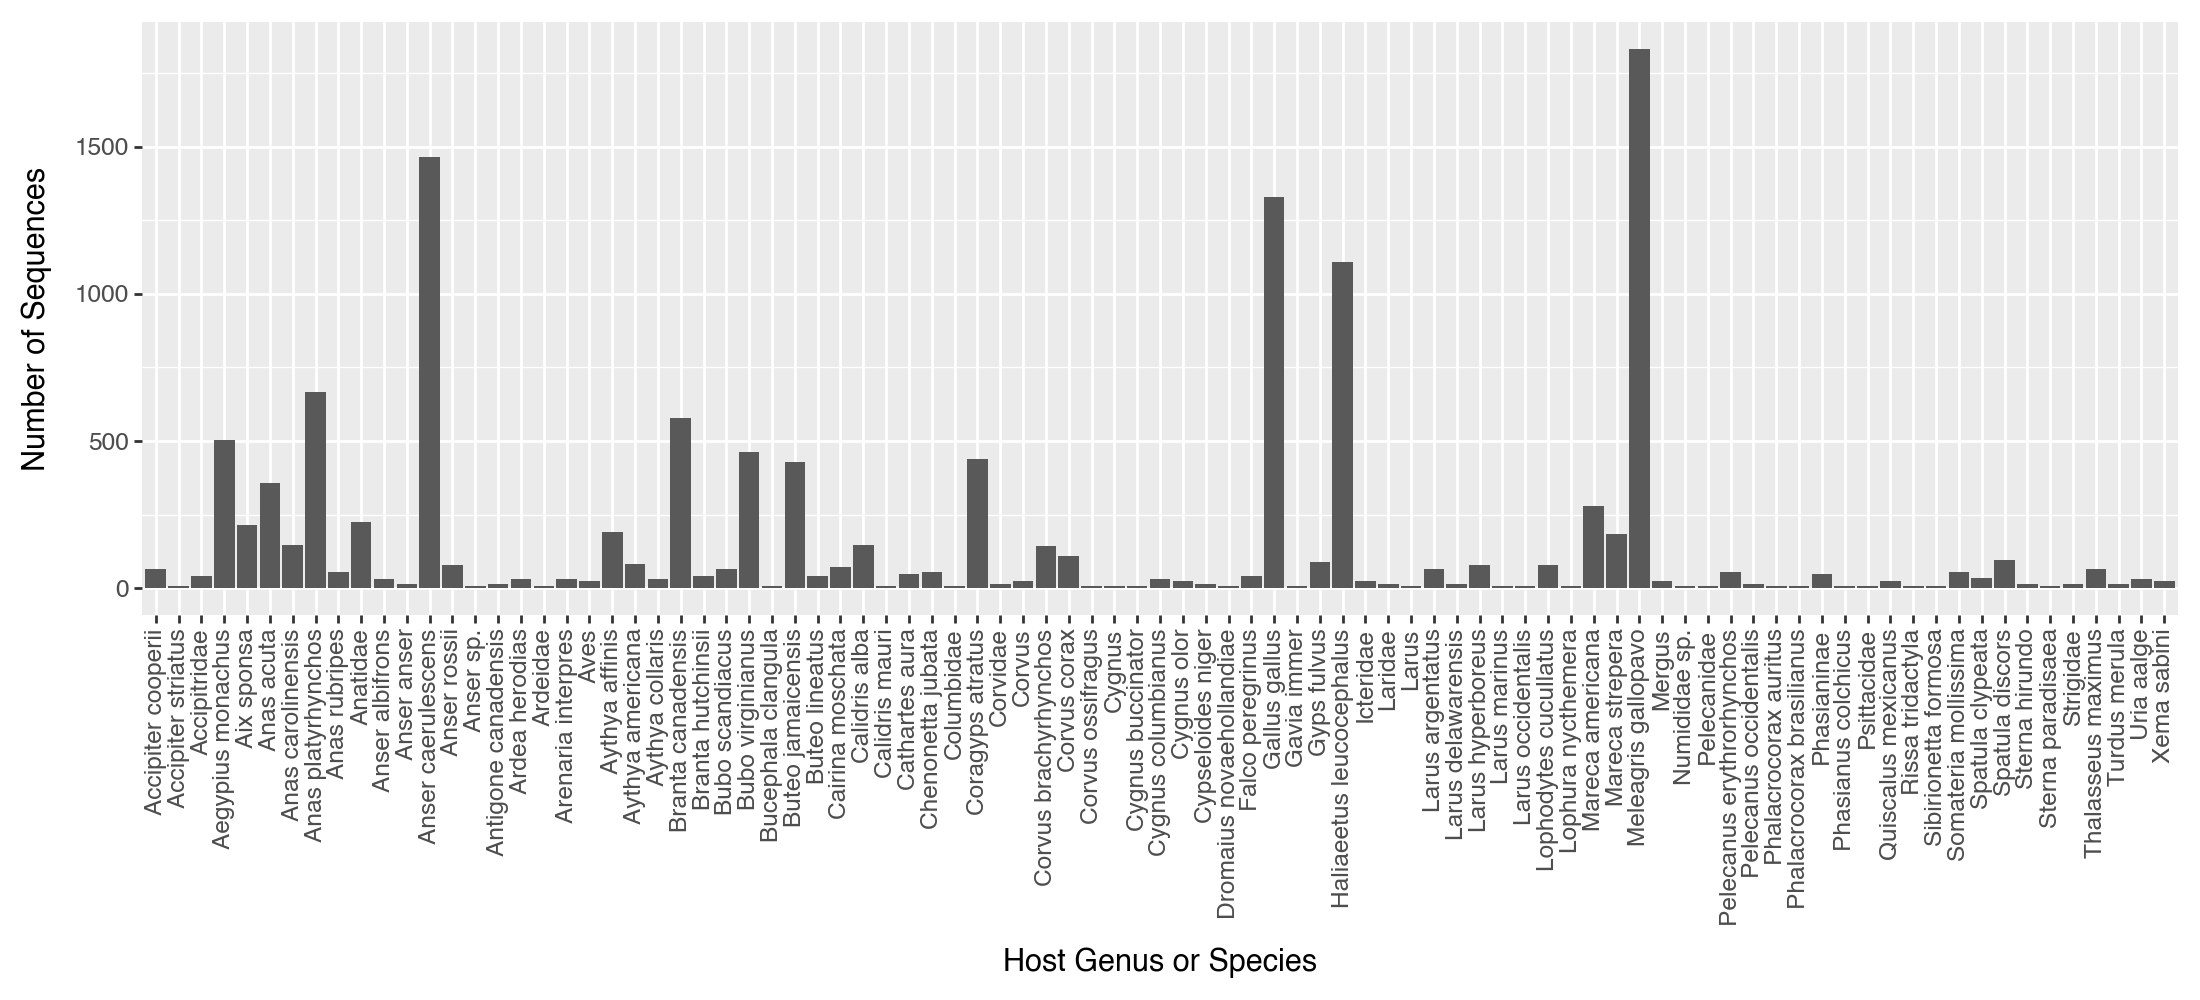

In [14]:
# To determine which bird orders are included in the metadata, first determine which bird species are in the metadata
included_avian_hosts = metadata_filtered["Host"].value_counts()
print(len(included_avian_hosts)) # So far, length is 89 species/genera/etc., but always check to see if that number changes

# Now make a plot of the included avian hosts
included_avian_hosts = included_avian_hosts.rename_axis("Host").reset_index()
included_avian_hosts = included_avian_hosts.sort_values(by = "count", ascending = False)
included_avian_hosts.head()

# plot this using ggplot
(
    ggplot(included_avian_hosts, aes(x = "Host", y = "count"))
    + geom_col()
    + labs(x = "Host Genus or Species", y = "Number of Sequences")
    + theme(axis_text_x = element_text(rotation = 90))
    + theme(figure_size=(11,5))
)

#included_avian_hosts.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/included_avian_hosts.csv", sep=",")

In [35]:
# The following are a number of dictionaries necessary for mapping onto the metadata

State_Latitude_Dict = {"alabama":32.7784,
                       "alaska":64.0610,
                       "arizona":34.2740,
                       "arkansas":34.8938,
                       "california":37.1992,
                       "colorado":38.9979,
                       "connecticut":41.6220,
                       "delaware":38.9895,
                       "florida":28.6282,
                       "georgia":32.6405,
                       "hawaii":20.2951, 
                       "idaho":44.3538,
                       "illinois":40.0411,
                       "indiana":39.8938,
                       "iowa":42.0753,
                       "kansas":38.4949,
                       "kentucky":37.5360,
                       "louisiana":31.0689,
                       "maine":45.3702,
                       "maryland":39.0550,
                       "massachusetts":42.2596,
                       "michigan":44.3461,
                       "minnesota":46.2810,
                       "mississippi":32.7351,
                       "missouri":38.3568,
                       "montana":47.0527,
                       "nebraska":41.5392,
                       "nevada":39.3306,
                       "new hampshire":43.6805,
                       "new jersey":40.1907,
                       "new mexico":34.4066,
                       "new york":42.9543,
                       "north carolina":35.5579,
                       "north dakota":47.4499,
                       "ohio":40.2863,
                       "oklahoma":35.5910,
                       "oregon":43.9336,
                       "pennsylvania":40.8786,
                       "rhode island":41.6762,
                       "south carolina":33.9169,
                       "south dakota":44.4446,
                       "tennessee":35.8605,
                       "texas":31.4789,
                       "utah":39.3057,
                       "vermont":44.0688,
                       "virginia":37.5229,
                       "washington":47.3822,
                       "west virginia":38.6409,
                       "wisconsin":44.6243,
                       "wyoming":42.9959,
                       #"temascalapa":, 
                       #"sonora":29.3846, 
                       #"libres":,
                       #"guanajuato":,
                       #"tehuitzingo":,
                       #"texcoco":,
                       #"veracruz":
                      } 

State_Longitude_Dict = {"alabama":-86.8290,
                       "alaska":-152.2307,
                       "arizona":-111.6582,
                       "arkansas":-92.4429,
                       "california":-119.4505,
                       "colorado":-105.5495,
                       "connecticut":-72.7272,
                       "delaware":-75.5051,
                       "florida":-82.4426,
                       "georgia":-83.4418,
                       "hawaii":-156.3720, 
                       "idaho":-114.6086,
                       "illinois":-89.1965,
                       "indiana":-86.2818,
                       "iowa":-93.4959,
                       "kansas":-98.3801,
                       "kentucky":-85.3021,
                       "louisiana":-91.9952,
                       "maine":-69.2438,
                       "maryland":-76.7909,
                       "massachusetts":-71.8083,
                       "michigan":-85.4114,
                       "minnesota":-94.3046,
                       "mississippi":-89.6680,
                       "missouri":-92.4571,
                       "montana":-109.645,
                       "nebraska":-99.7968,
                       "nevada":-116.6268,
                       "new hampshire":-71.5818,
                       "new jersey":-74.6733,
                       "new mexico":-106.1128,
                       "new york":-75.5262,
                       "north carolina":-79.3856,
                       "north dakota":-100.4674,
                       "ohio":-82.7938,
                       "oklahoma":-97.4943,
                       "oregon":-120.5617,
                       "pennsylvania":-77.7985,
                       "rhode island":-71.5562,
                       "south carolina":-80.8957,
                       "south dakota":-100.2282,
                       "tennessee":-86.3504,
                       "texas":-99.3287,
                       "utah":-111.6685,
                       "vermont":-72.6663,
                       "virginia":-78.8531,
                       "washington":-120.4505,
                       "west virginia":-80.6230,
                       "wisconsin":-89.9941,
                       "wyoming":-107.5527,
                       #"temascalapa":, 
                       #"sonora":-110.5208, 
                       #"libres":,
                       #"guanajuato":,
                       #"tehuitzingo":,
                       #"texcoco":,
                       #"veracruz":
                       }

In [16]:
def check_duplicates(df):
    df["strain"] = df["GenBank_Title"].str.extract(pat = r"(A[\/].*[\/]\d{4})", flags = 0, expand = True)
    df["strain"] = df["strain"].str.lower()
    df["strain"] = df["strain"].str.replace("-", "")
    return print(df["strain"].is_unique)

# def format_date(datestr):
#     i = str(datestr)
#     date_object = datetime.strptime(i, '%Y-%m-%d')
#     return (date_object)

In [17]:
# Make strain column
metadata_filtered.pipe(check_duplicates)

False


/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_67494/2926143913.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_67494/2926143913.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_67494/2926143913.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docume

In [22]:
# Get state from strain name

# Extract state from strain name
strain_split = metadata_filtered["strain"].str.split(pat = "/", expand = True)
#print(strain_split)

# Add State to metadata_filtered
metadata_filtered["State"] = strain_split[2]
#metadata_filtered.head()

/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_67494/1210441661.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [25]:
# Fix the State column
print(set(metadata_filtered["State"]))

metadata_filtered["State"] = metadata_filtered["State"].replace(to_replace = ("az", "oh", "de", "md", "fl", "flordia", "louisana"), 
                                                                value = ("arizona", "ohio", "delaware", "maryland", "florida", "florida", "louisiana"))

print(set(metadata_filtered["State"]))

{'montana', 'wyoming', 'georgia', 'florida', 'sonora', 'new jersey', 'south carolina', 'maryland', 'veracruz', 'oregon', 'idaho', 'missouri', 'washington', 'arizona', 'texas', 'north dakota', 'alabama', 'temascalapa', 'wisconsin', 'tennessee', 'kentucky', 'michigan', 'texcoco', 'illinois', 'kansas', 'minnesota', 'libres', 'connecticut', 'maine', 'utah', 'iowa', 'new york', 'north carolina', 'colorado', 'delaware', 'louisiana', 'usa', 'guanajuato', 'virginia', 'south dakota', 'ohio', 'nebraska', 'california', 'new mexico', 'pennsylvania', 'massachusetts', 'oklahoma', 'indiana', 'tehuitzingo', 'new hampshire', 'alaska', 'vermont'}
{'montana', 'wyoming', 'georgia', 'florida', 'sonora', 'new jersey', 'south carolina', 'maryland', 'veracruz', 'oregon', 'idaho', 'missouri', 'washington', 'arizona', 'texas', 'north dakota', 'alabama', 'temascalapa', 'wisconsin', 'tennessee', 'kentucky', 'michigan', 'texcoco', 'illinois', 'kansas', 'minnesota', 'libres', 'connecticut', 'maine', 'utah', 'iowa',

/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_67494/397758557.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [88]:
# Just to check in at this point:
# I have filtered for just the sequences that have full YYYY-MM-DD dates: metadata_filtered
# I have added a Collection_datetime column that is the same as Collection_date but in datetime format: metadata_filtered
# I have added a column with state data: metadata_filtered

In [31]:
# Add columns for flyways

# Upload flyways dataframe
flyways = pd.read_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/flywayregions.csv", sep = ",", dtype={'location':str})
column_mapper = {"location":"State"}
flyways = flyways.rename(mapper = column_mapper, axis = 1)
flyways["State"] = flyways["State"].str.lower()

# Add Mexican states to flyways dataframe
mexico_flyways = pd.DataFrame({"State":["temascalapa", "sonora", "libres", "guanajuato", "tehuitzingo", "texcoco", "veracruz"],
        "flyway":["Central Flyway", "Pacific Flyway", "Central Flyway", "Central Flyway", "Central Flyway", "Central Flyway", "Central Flyway"],
        "geo_region_na":["Mexico", "Mexico", "Mexico", "Mexico", "Mexico", "Mexico", "Mexico"]
       })
flyways_updt = flyways._append(mexico_flyways, ignore_index = True)

# Add flyways to metadata

metadata_filtered_flyways = pd.merge(metadata_filtered, flyways_updt, on = "State", how = "outer")
#metadata_filtered_flyways.head()
print(len(metadata_filtered_flyways)) 
# When added how="outer" to the merge, now have 12,891 of 13,327 rows and state-less sequences are still included
#metadata_filtered_flyways.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/metadata_filtered_flyways.csv", sep=",")

12891


In [32]:
# If I want to limit to just US states, I can use the following code

#states_to_keep = set(metadata_USA["Geo_State"])
#US_flyways = flyways[flyways["Geo_State"].isin(states_to_keep)]
#non_US_flyways = set(flyways["Geo_State"])-states_to_keep

In [34]:
# Add columns for host bird order

birdies = pd.read_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/included_avian_hosts.csv", sep = ",")

metadata_filtered_flyways_birdies = pd.merge(metadata_filtered_flyways, birdies, on="Host")
print(len(metadata_filtered_flyways_birdies)) #Length of this is 12,870 (missing 21 rows from previous)
#metadata_filtered_flyways_birdies.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/metadata_filtered_flyways_birdies.csv", sep=",")

12870


In [36]:
# Add columns for latitide and longitude

metadata_filtered_flyways_birdies["State_Lat"] = metadata_filtered_flyways_birdies["State"].map(State_Latitude_Dict)
metadata_filtered_flyways_birdies["State_Long"] = metadata_filtered_flyways_birdies["State"].map(State_Longitude_Dict)
metadata_filtered_flyways_birdies["Centroid_Coord"] = metadata_filtered_flyways_birdies["State_Lat"].astype(str) + ',' + metadata_filtered_flyways_birdies["State_Long"].astype(str)

In [39]:
list(metadata_filtered_flyways_birdies.columns)

['Accession',
 'Organism_Name',
 'SRA_Accession',
 'Organization',
 'Org_location',
 'Release_Date',
 'Isolate',
 'Species',
 'Molecule_type',
 'Length',
 'Sequence_Type',
 'Nuc_Completeness',
 'Genotype',
 'Segment',
 'Geo_Location',
 'Country',
 'USA',
 'Host',
 'Isolation_Source',
 'Collection_Date',
 'BioSample',
 'BioProject',
 'GenBank_Title',
 'Collection_datetime',
 'strain',
 'State',
 'flyway',
 'geo_region_na',
 'count',
 'commonname',
 'broad',
 'order',
 'domesticstatus',
 'notes',
 'State_Lat',
 'State_Long',
 'Centroid_Coord']

In [40]:
# Drop all the excess columns you made

drop_columns = ["count", "commonname", "broad", "notes", "geo_region_na", "Geo_Location", "State_Lat", "State_Long"]
metadata_datetime_bird_flyway_coord = metadata_filtered_flyways_birdies.drop(labels=drop_columns, axis = 1)
metadata_datetime_bird_flyway_coord.head()

,Accession,Organism_Name,SRA_Accession,Organization,Org_location,Release_Date,Isolate,Species,Molecule_type,Length,...,BioSample,BioProject,GenBank_Title,Collection_datetime,strain,State,flyway,order,domesticstatus,Centroid_Coord
0,OQ957841.1,Influenza A virus,NaN,"United States Department of Agriculture, Agric...",USA,2023-08-23,22-004941-003,Alphainfluenzavirus influenzae,ssRNA(-),2280.0,...,NaN,NaN,Influenza A virus (A/American Wigeon/Alabama/2...,2022-02-05,a/american wigeon/alabama/22004941003/2022,alabama,Mississippi Flyway,anseriformes,wild,"32.7784,-86.829"
1,OQ957842.1,Influenza A virus,NaN,"United States Department of Agriculture, Agric...",USA,2023-08-23,22-004941-003,Alphainfluenzavirus influenzae,ssRNA(-),2274.0,...,NaN,NaN,Influenza A virus (A/American Wigeon/Alabama/2...,2022-02-05,a/american wigeon/alabama/22004941003/2022,alabama,Mississippi Flyway,anseriformes,wild,"32.7784,-86.829"
2,OQ957843.1,Influenza A virus,NaN,"United States Department of Agriculture, Agric...",USA,2023-08-23,22-004941-003,Alphainfluenzavirus influenzae,ssRNA(-),2151.0,...,NaN,NaN,Influenza A virus (A/American Wigeon/Alabama/2...,2022-02-05,a/american wigeon/alabama/22004941003/2022,alabama,Mississippi Flyway,anseriformes,wild,"32.7784,-86.829"
3,OQ957844.1,Influenza A virus,NaN,"United States Department of Agriculture, Agric...",USA,2023-08-23,22-004941-003,Alphainfluenzavirus influenzae,ssRNA(-),1704.0,...,NaN,NaN,Influenza A virus (A/American Wigeon/Alabama/2...,2022-02-05,a/american wigeon/alabama/22004941003/2022,alabama,Mississippi Flyway,anseriformes,wild,"32.7784,-86.829"
4,OQ957845.1,Influenza A virus,NaN,"United States Department of Agriculture, Agric...",USA,2023-08-23,22-004941-003,Alphainfluenzavirus influenzae,ssRNA(-),1497.0,...,NaN,NaN,Influenza A virus (A/American Wigeon/Alabama/2...,2022-02-05,a/american wigeon/alabama/22004941003/2022,alabama,Mississippi Flyway,anseriformes,wild,"32.7784,-86.829"


In [41]:
# Another check in:
# I have filtered for just the sequences that have full YYYY-MM-DD dates: metadata_filtered
# I have added a Collection_datetime column that is the same as Collection_date but in datetime format: metadata_filtered
# I have added a separate State column: metadata_filtered
# I have addded the corresponding flyway data: metadata_filtered_flyways
# I have added the corresponding host (bird) taxonomic order and domestic status: metadata_filtered_flyways_birdies
# I have added the corresponding latitude and longitude: metadata_datetime_bird_flyway_coord

In [42]:
# Save as an updated TSV
metadata_datetime_bird_flyway_coord.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/sequence_metadata/updated_metadata_07012024.tsv", sep = '\t')

In [43]:
# Because each isolate has multiple segments, we want to split the big metadata file into separate files by segment

segment1_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 1] # Encodes PB2 
segment2_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 2] # Encodes PB1 and sometimes PB1-F2
segment3_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 3] # Encodes PA
segment4_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 4] # Encodes HA
segment5_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 5] # Encodes NP
segment6_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 6] # Encodes NA
segment7_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 7] # Encodes M1 matrix
segment8_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 8] # Encodes NS1, NEP, and NS2

print(len(segment1_metadata))
#segment1_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment1_metadata_07012024.csv", sep=',')
print(len(segment2_metadata))
#segment2_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment2_metadata_07012024.csv", sep=',')
print(len(segment3_metadata))
#segment3_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment3_metadata_07012024.csv", sep=',')
print(len(segment4_metadata))
#segment4_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment4_metadata_07012024.csv", sep=',')
print(len(segment5_metadata))
#segment5_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment5_metadata_07012024.csv", sep=',')
print(len(segment6_metadata))
#segment6_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment6_metadata_07012024.csv", sep=',')
print(len(segment7_metadata))
#segment7_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment7_metadata_07012024.csv", sep=',')
print(len(segment8_metadata))
#segment8_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment8_metadata_07012024.csv", sep=',')
# adds up to 12,870 (good!)

1585
1592
1599
1621
1617
1618
1618
1620


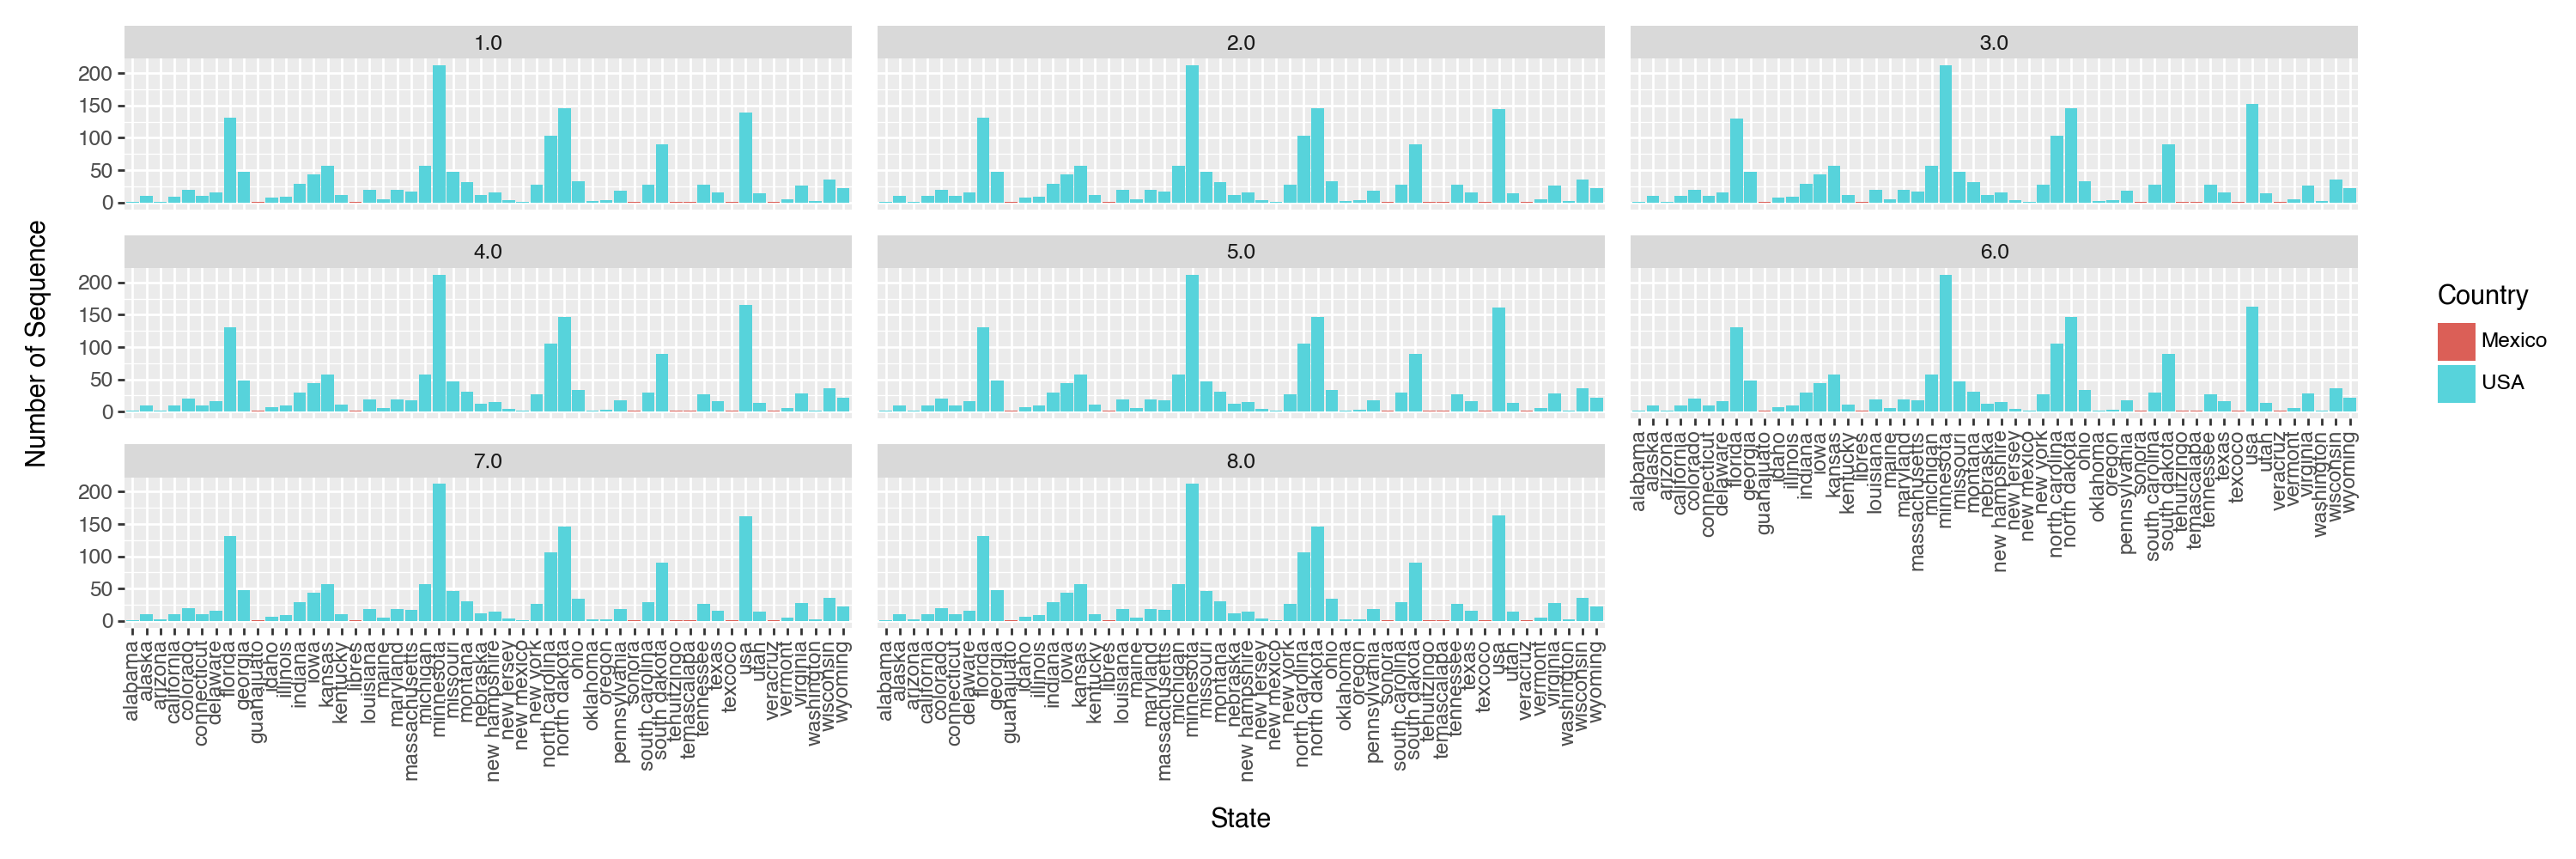

In [44]:
# The following script investigates how many sequences have state-level collection location data

# Make a dataframe of the number of sequences from each state 
metadata_states = pd.DataFrame(metadata_datetime_bird_flyway_coord["State"].value_counts())
metadata_states = metadata_states.rename_axis("State").reset_index()
#print(metadata_states)

# Plot this data using ggplot
# (
# ggplot(metadata_states, aes(x = "State", y = "count")) 
#     + geom_col()
#     + labs(x = "State", y = "Number of Sequences")
#     #+ axis_text_x(element_text(rotation = "vertical"))
#     #+ element_text(axis_text_x(rotation = "vertical"))
#     + theme(axis_text_x = element_text(rotation = 90))
# )

# Plot sequences by state, facetted by segment
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "State", fill = "Country"))
    + geom_bar(stat = "count")
    + facet_wrap("Segment")
    + labs(x = "State", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (15, 5))
)

/Users/claramal/miniconda3/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10


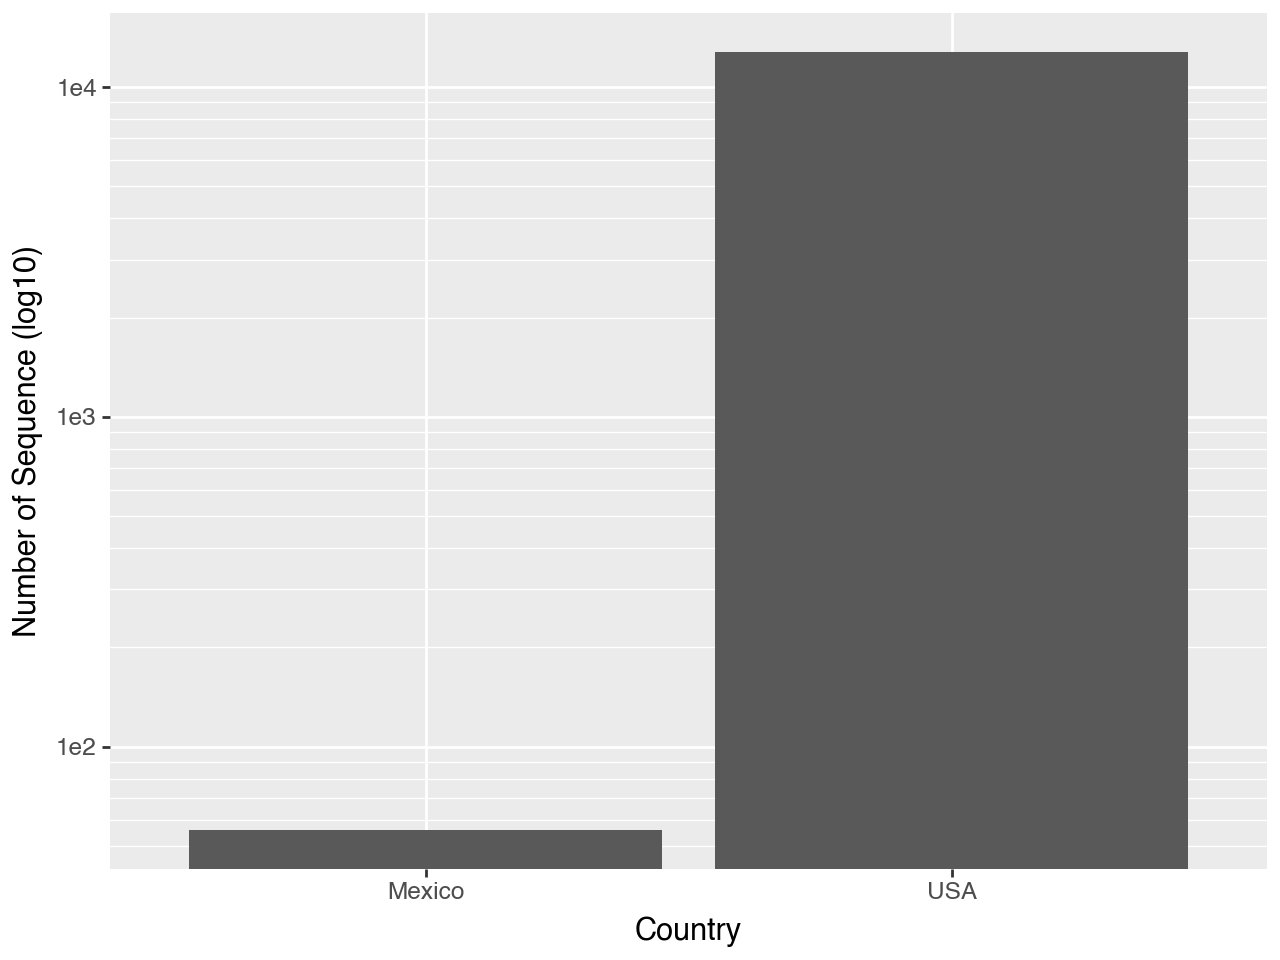

In [50]:
# Plot sequences state, facetted by country, because I'm curious
# (
#     ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Geo_State", fill = "Country"))
#     + geom_bar(stat = "count")
#     + facet_wrap("Country")
#     + labs(x = "State", y = "Number of Sequence")
#     + theme(axis_text_x = element_text(rotation = 90), figure_size = (13, 5))
# )

# Or just by country, either one
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Country"))
    + geom_bar(stat = "count")
    + labs(x = "Country", y = "Number of Sequence (log10)")
    + scale_y_log10()
#    + theme(axis_text_x = element_text(rotation = 90), figure_size = (13, 5))
)

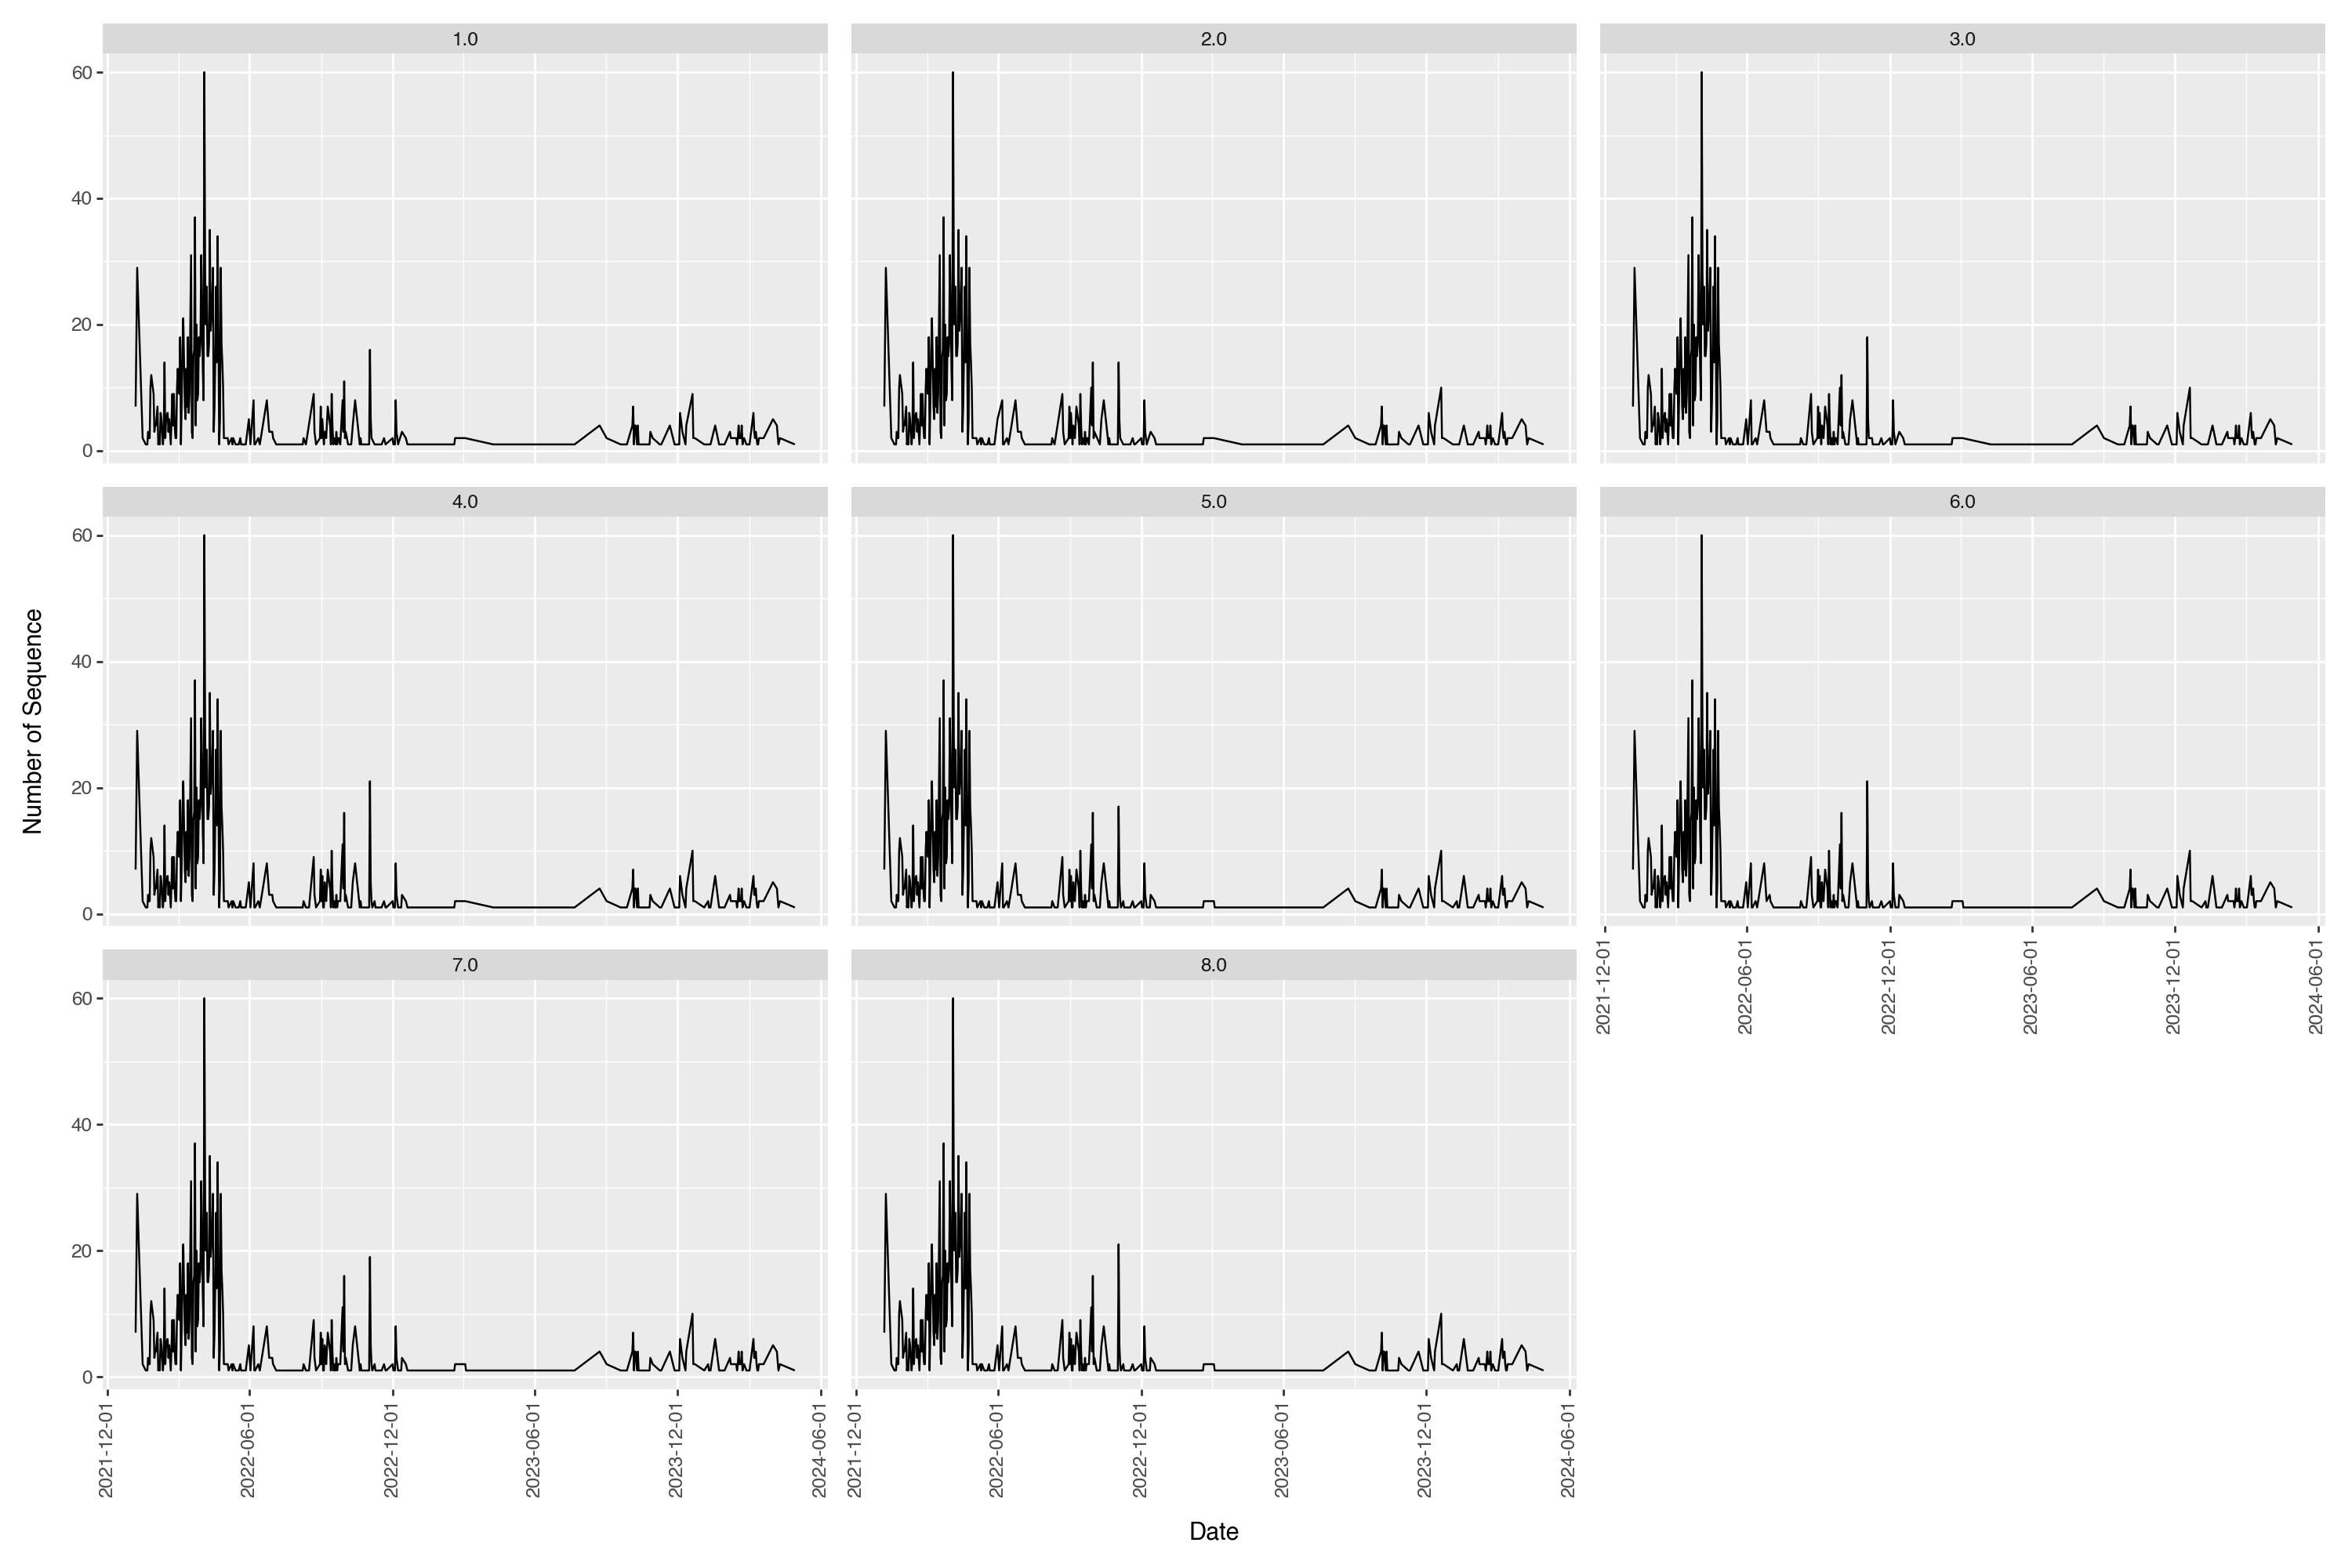

In [23]:
# Plot the number of sequences by date
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Collection_datetime"))
    + geom_line(stat = "count")
    + facet_wrap("Segment")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (15, 10))
)

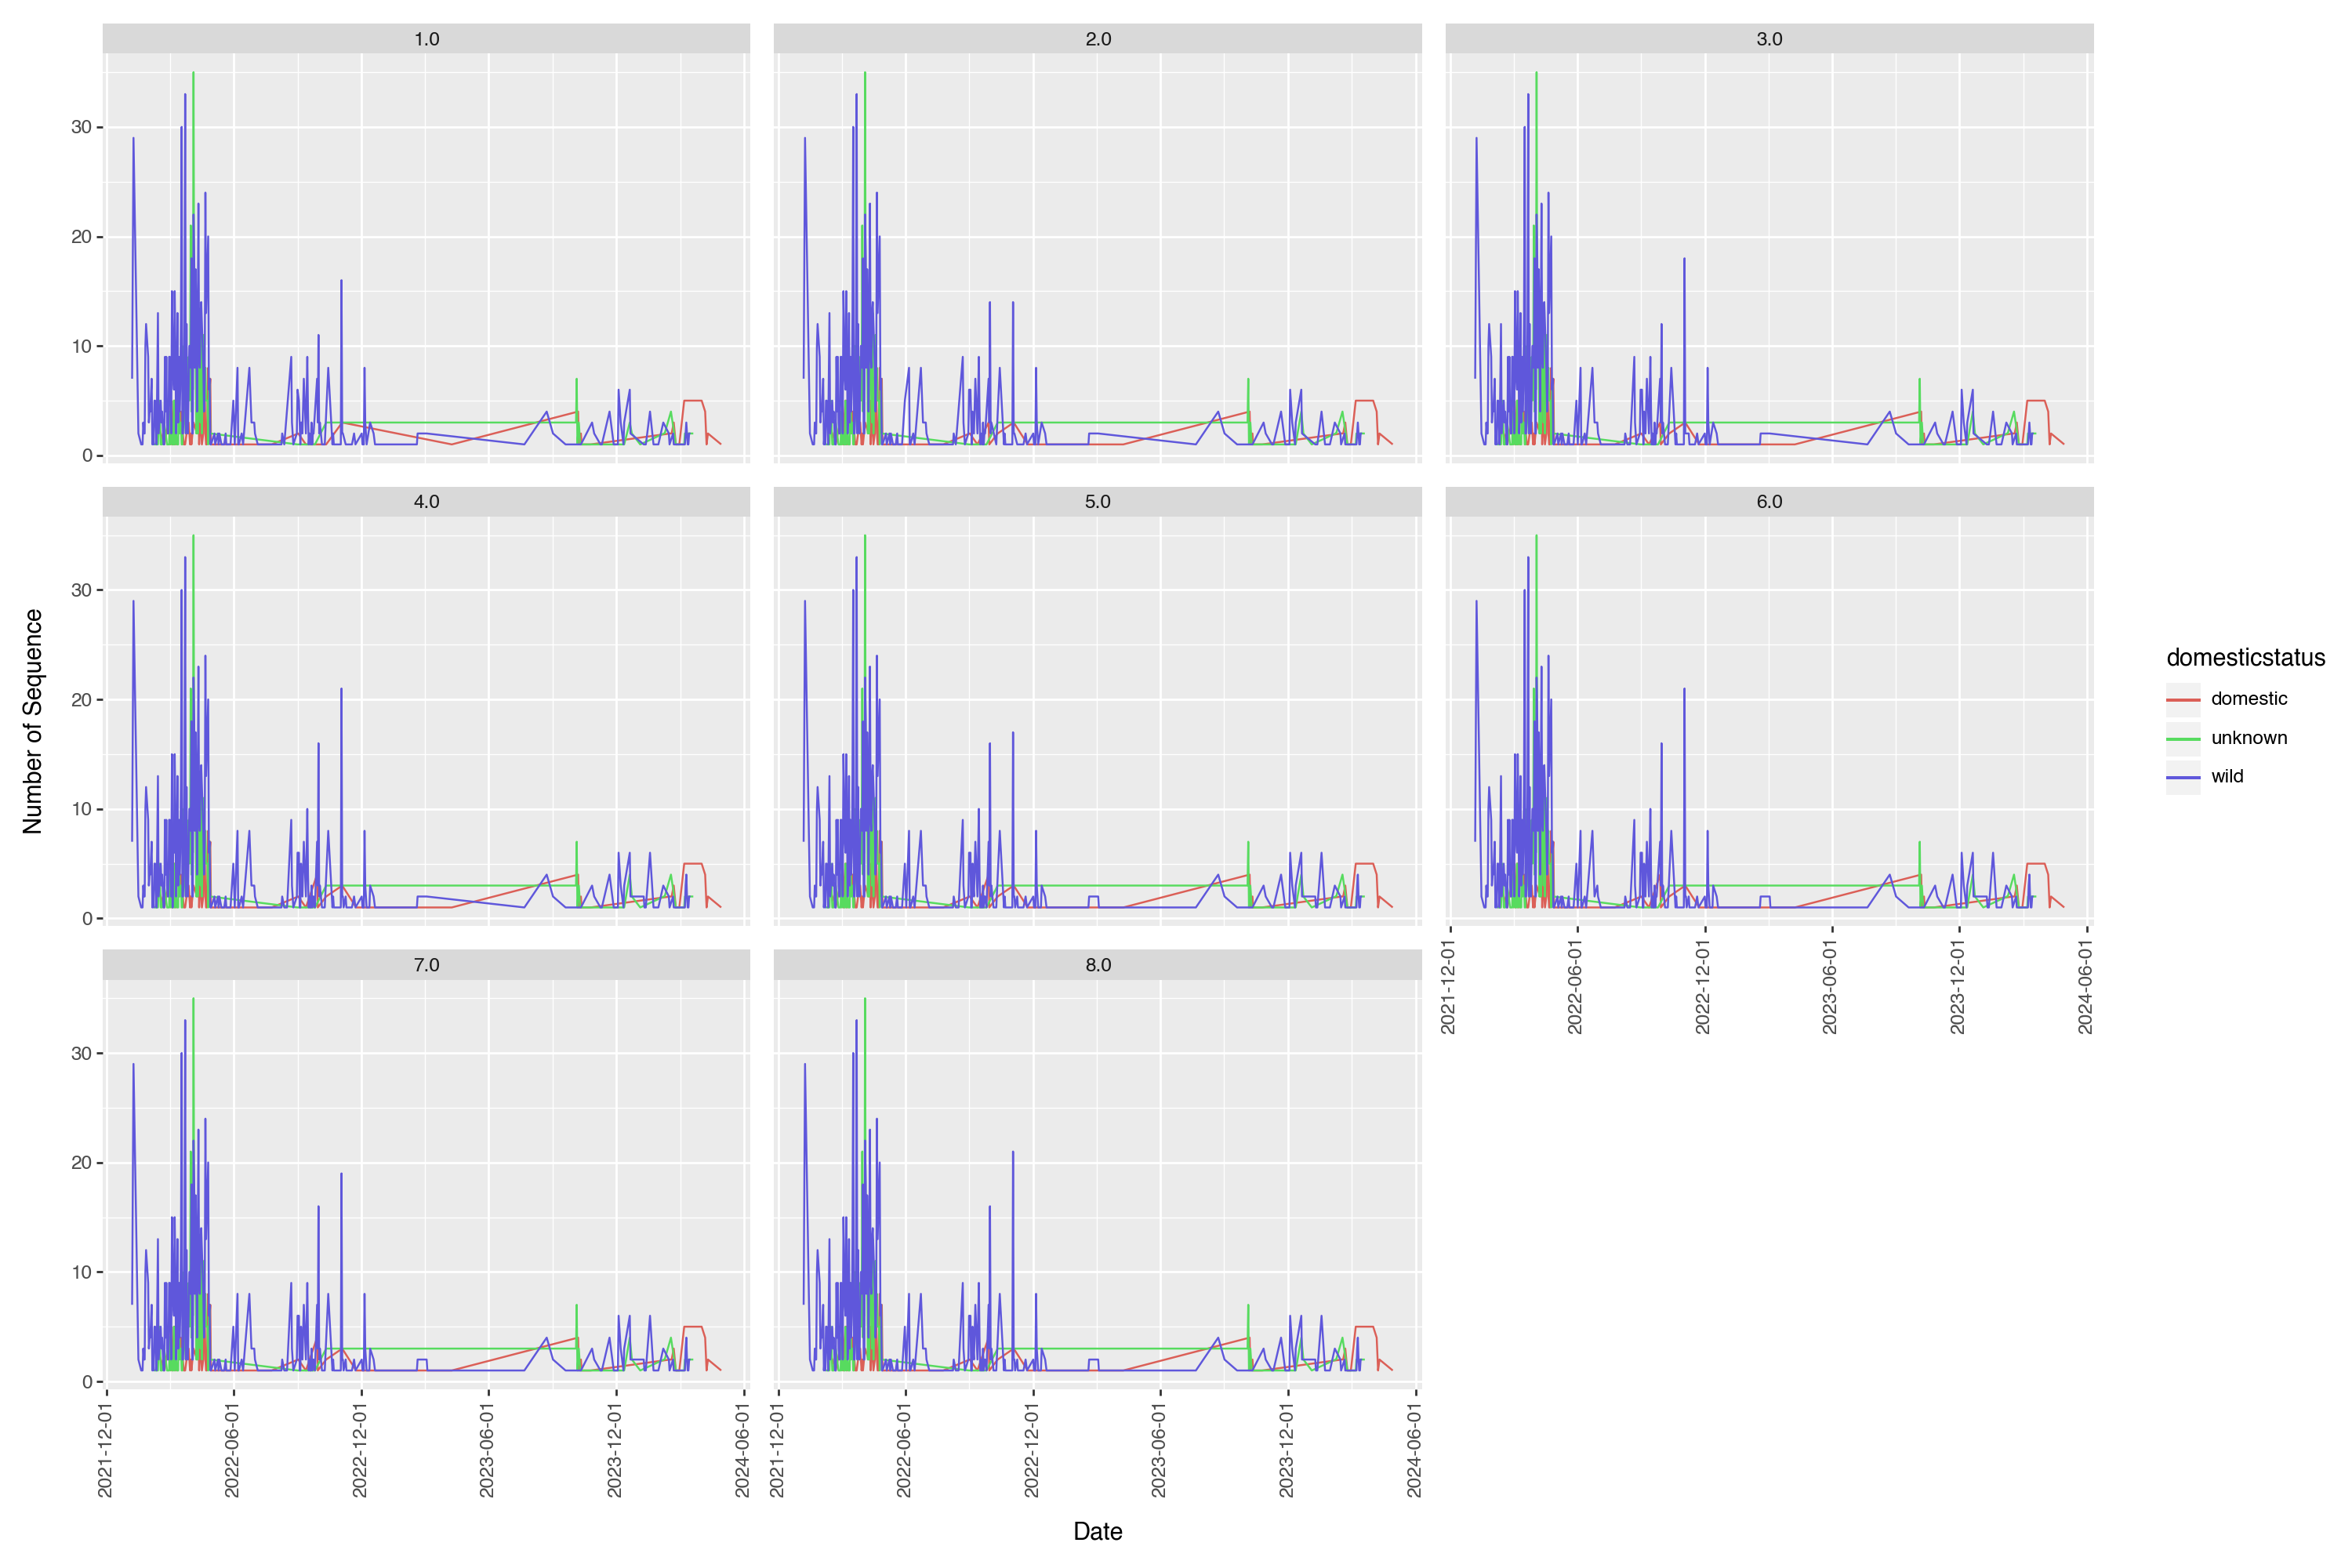

In [24]:
# Plot Sequences over time, with one line for wild birds and one line for domestic birds, facetted by segment
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Collection_datetime", color = "domesticstatus"))
    + geom_line(stat = "count")
    + facet_wrap("Segment")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (15, 10))
)

In [51]:
# How many sequences per flyway
metadata_datetime_bird_flyway_coord["flyway"].value_counts()

flyway
Mississippi Flyway    4205
Atlantic Flyway       3804
Central Flyway        3224
Pacific Flyway         388
Name: count, dtype: int64

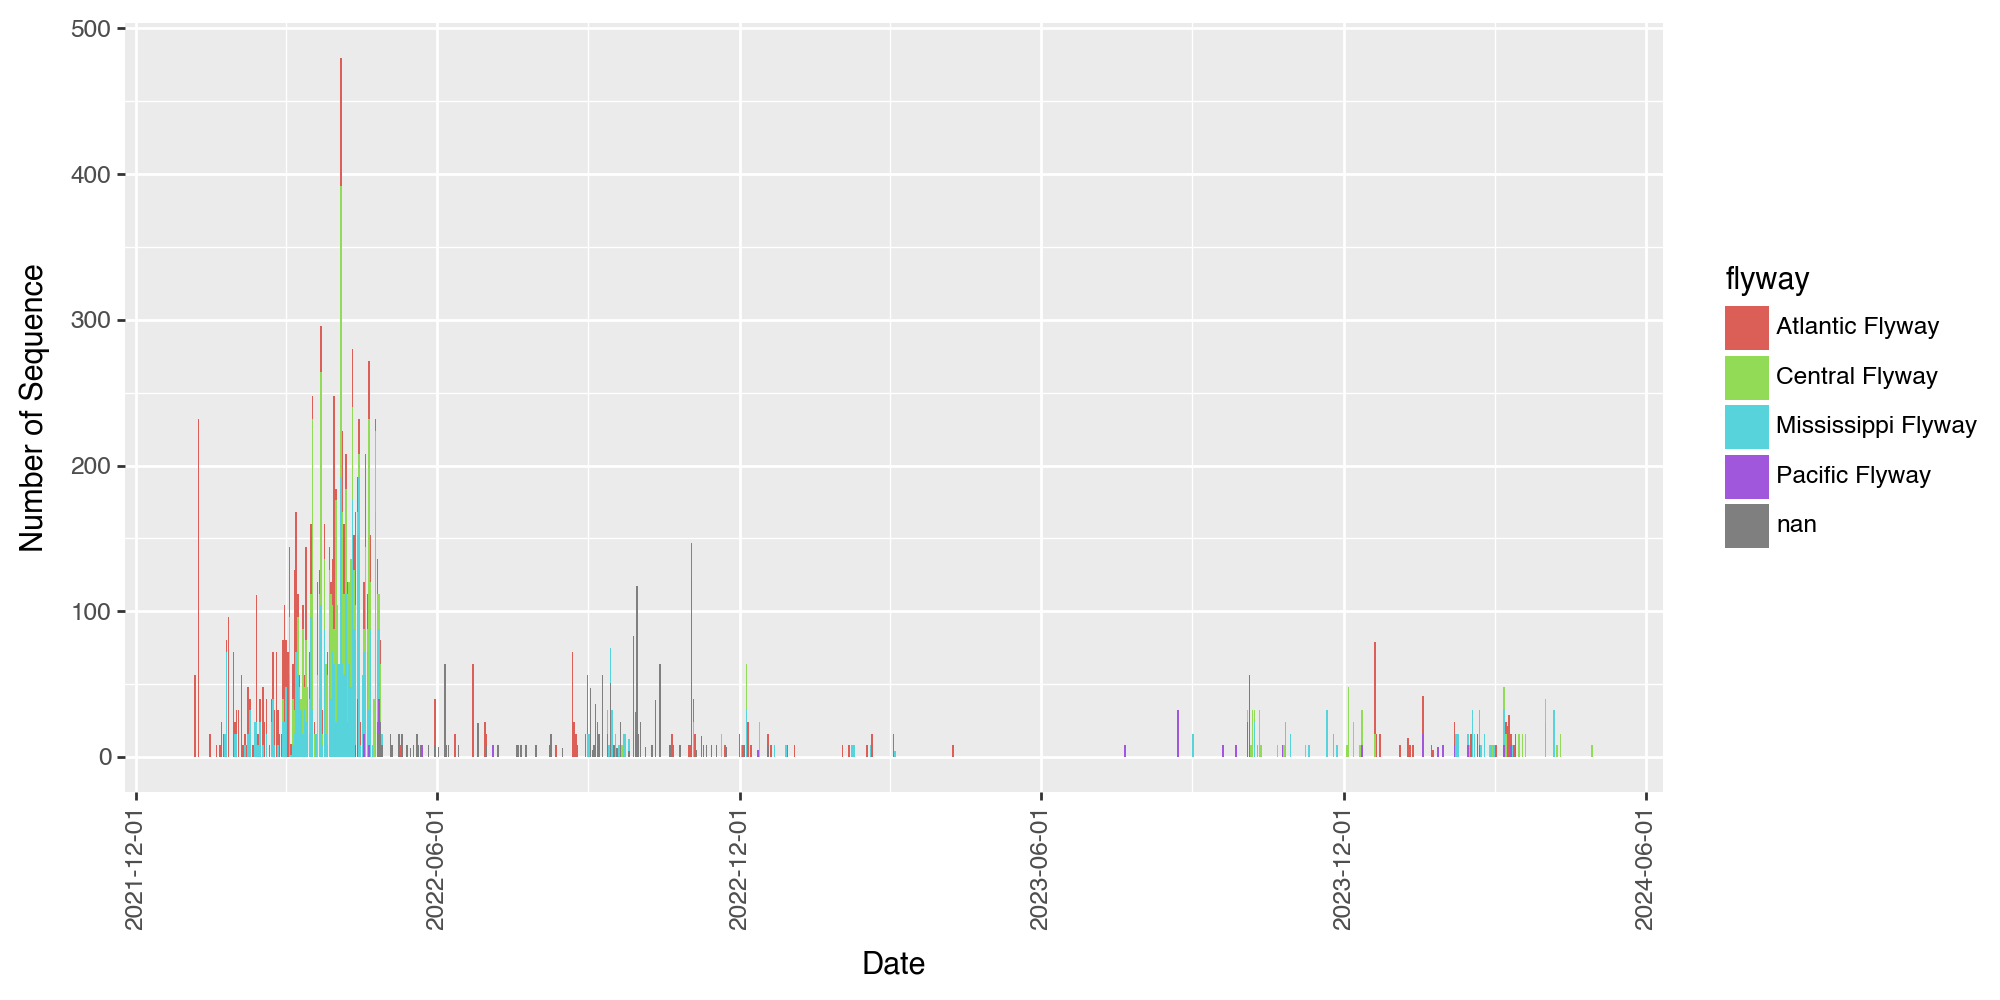

In [54]:
# Plot sequences over time, by flyway
# (
#     ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Collection_datetime", color = "flyway"))
#     + geom_line(stat = "count")
# #    + facet_wrap("Segment")
#     + labs(x = "Date", y = "Number of Sequence")
#     + theme(axis_text_x = element_text(rotation = 90), figure_size = (10, 5))
# )

# I don't love this as a line graph... what about as a bar graph
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Collection_datetime", fill = "flyway"))
    + geom_bar(stat = "count", size = 10)
#    + facet_wrap("Segment")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (10, 5))
)

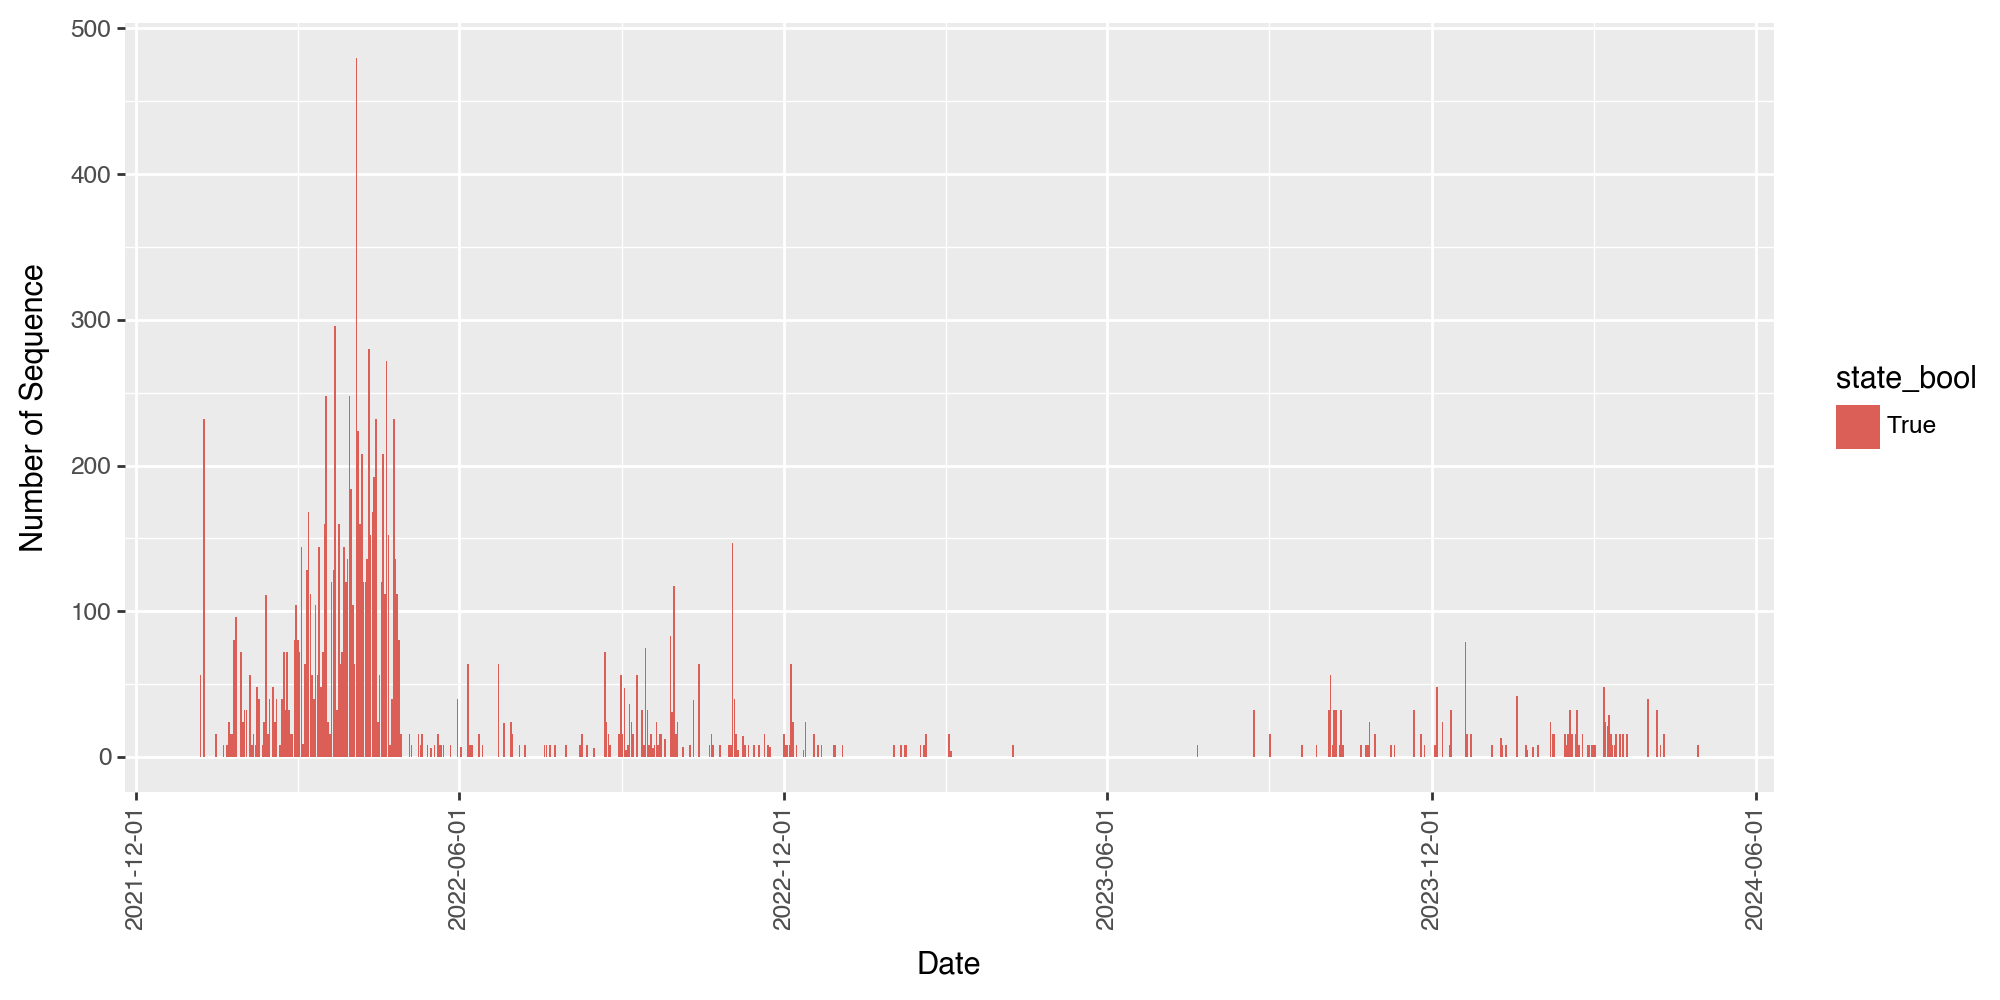

In [55]:
# Why are we losing flyway data after the first 6 mo? Is it because we're loosing state data

# New column if there is a state or not
metadata_datetime_bird_flyway_coord["state_bool"] = metadata_datetime_bird_flyway_coord["State"].apply(lambda x: bool(x) if pd.notna(x) else False)
#print(metadata_datetime_bird_flyway_coord["state_bool"])

# Plot
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Collection_datetime", fill = "state_bool"))
    + geom_bar(stat = "count")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (10, 5))
)

In [67]:
# Check duplicates in strain name for each segment database

print(segment1_metadata["strain"].is_unique)
print(segment2_metadata["strain"].is_unique)
print(segment3_metadata["strain"].is_unique)
print(segment4_metadata["strain"].is_unique)
print(segment5_metadata["strain"].is_unique)
print(segment6_metadata["strain"].is_unique)
print(segment7_metadata["strain"].is_unique)
print(segment8_metadata["strain"].is_unique)

False
False
False
False
False
False
False
False


In [ ]:
# Everything below this is old code that is not being used (but may yet be helpful!)

In [47]:
# Toying with pulling out strain name here

# Step 1: pull out the strain name and make it a new column
#strain_name = metadata_datetime_bird_flyway_coord["GenBank_Title"].str.extract(pat = r"(A[\/].*[\/]\d{4})", flags = 0, expand = True)
metadata_datetime_bird_flyway_coord["strain"] = metadata_datetime_bird_flyway_coord["GenBank_Title"].str.extract(pat = r"(A[\/].*[\/]\d{4})", flags = 0, expand = True)
#print(metadata_datetime_bird_flyway_coord["strain"])
#strain_bool = metadata_datetime_bird_flyway_coord["GenBank_Title"].str.contains("A[\/].*[\/]\d{4}\(H5N\w\)", case = True, flags = 0, regex = True)

# Step 2: remove all uppercases, dashes, hyphens
metadata_datetime_bird_flyway_coord["strain"] = metadata_datetime_bird_flyway_coord["strain"].str.lower()
metadata_datetime_bird_flyway_coord["strain"] = metadata_datetime_bird_flyway_coord["strain"].str.replace("-", "")

# Step 3: check if there are any duplicates within each segment file
metadata_datetime_bird_flyway_coord["strain"].is_unique

# Now I have to make this into a function

False

In [87]:
# # This was an old method of extracting state data

# # Separate country and state 

# # Geo_Country and Geo_State columns (to put the State data in its own column)
# split = metadata_filtered["Geo_Location"].str.split(pat = ':', expand = True)
# metadata_filtered["Geo_Country"] = split[0]
# metadata_filtered["Geo_State"] = split[1]
# metadata_filtered["Geo_State"] = metadata_filtered["Geo_State"].str.strip()

# # Change OH and Maricopa County to correct states
# metadata_filtered["Geo_State"] = metadata_filtered["Geo_State"].replace(to_replace = ("OH", "Maricopa County, AZ"), value = ("Ohio", "Arizona"))

# #metadata_USA = metadata_filtered[metadata_filtered["Country"] == "USA"]
# print(set(metadata_filtered["Geo_State"]))

In [ ]:
# infile = updated_metadata_07012024.csv # or as TSV, depending on how you save it
# strain_dict = {}
# for line in infile:
#     strain_name = 
#     if strain in strain_dict
#     else:
#         strain_dict[strain_name] = {}